**STEP 1 — Experimental Framework Consolidation**


The previous notebooks evaluated multiple approaches for estimating confidence in large language model predictions.

These approaches included:

- Baseline confidence estimation
- Calibration methods
- Option likelihood uncertainty signals
- Multi-signal confidence fusion

Each method was evaluated independently using discrimination, calibration and selective prediction metrics.

The objective of this notebook is to bring all experimental findings together into a unified evaluation framework.



Individual experiments provide useful insights, but they do not directly answer the dissertation research questions.

A final comparative evaluation is required to determine:

- which method performs best overall
- which method provides the strongest calibration
- which method produces the most reliable uncertainty estimates
- whether multi-signal confidence estimation offers meaningful advantages over existing approaches

**STEP 1.1 — Import Libraries**

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

**STEP 1.2 — Load Previous Experimental Results**

In [2]:
base_path = "/content/drive/MyDrive/Dissertation/"

signal_correctness = pd.read_csv(
    base_path + "signal_correctness_ranking.csv"
)

signal_calibration = pd.read_csv(
    base_path + "signal_calibration_ranking.csv"
)

signal_selective = pd.read_csv(
    base_path + "signal_selective_prediction_ranking.csv"
)

multi_signal = pd.read_csv(
    base_path + "multi_signal_final_summary.csv"
)

baseline_predictions = pd.read_csv(
    base_path + "/baseline_option_scores.csv"
)

print("Files loaded successfully.")

Files loaded successfully.


**STEP 1.3 — Verify Loaded Data**

In [3]:
print("="*60)
print("SIGNAL CORRECTNESS")
print("="*60)

display(signal_correctness.head())

print("="*60)
print("SIGNAL CALIBRATION")
print("="*60)

display(signal_calibration.head())

print("="*60)
print("SIGNAL SELECTIVE PREDICTION")
print("="*60)

display(signal_selective.head())

print("="*60)
print("MULTI SIGNAL")
print("="*60)

display(multi_signal.head())

SIGNAL CORRECTNESS


,Signal,Correlation,ROC_AUC
0,probability_gap,0.399033,0.752871
1,margin_score,0.399033,0.752871
2,normalised_entropy,-0.320993,0.685422
3,confidence,0.318324,0.685464
4,entropy,-0.119717,0.576799


SIGNAL CALIBRATION


,Signal,ECE,Rank,Mean_ECE,CI_Lower,CI_Upper
0,Confidence,0.158951,1,0.161613,0.129822,0.194831
1,Margin Score,0.396015,2,0.397507,0.366067,0.429425
2,Probability Gap,0.396015,3,0.397152,0.365704,0.428119
3,Normalised Entropy,0.450674,4,0.450541,0.417985,0.483019


SIGNAL SELECTIVE PREDICTION


,Signal,AURC,Mean_AURC,CI_Lower,CI_Upper,Rank
0,Margin Score,0.296035,0.294905,0.257514,0.333155,1
1,Probability Gap,0.296035,0.294711,0.257794,0.333849,2
2,Normalised Entropy,0.329494,0.328695,0.288611,0.375227,3
3,Confidence,0.349734,0.349399,0.303937,0.392170,4


MULTI SIGNAL


,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
0,Fused,0.731001,0.042918,0.304046,1.0,1.0,1.0,3.0
1,Baseline,0.685464,0.158951,0.349734,2.0,2.0,2.0,6.0


In [4]:
print("="*60)
print("DATA LOADED SUCCESSFULLY")
print("="*60)

print(f"Correctness Results : {len(signal_correctness)} signals")
print(f"Calibration Results : {len(signal_calibration)} signals")
print(f"Selective Prediction Results : {len(signal_selective)} signals")
print(f"Fusion Results : {len(multi_signal)} methods")

DATA LOADED SUCCESSFULLY
Correctness Results : 5 signals
Calibration Results : 4 signals
Selective Prediction Results : 4 signals
Fusion Results : 2 methods


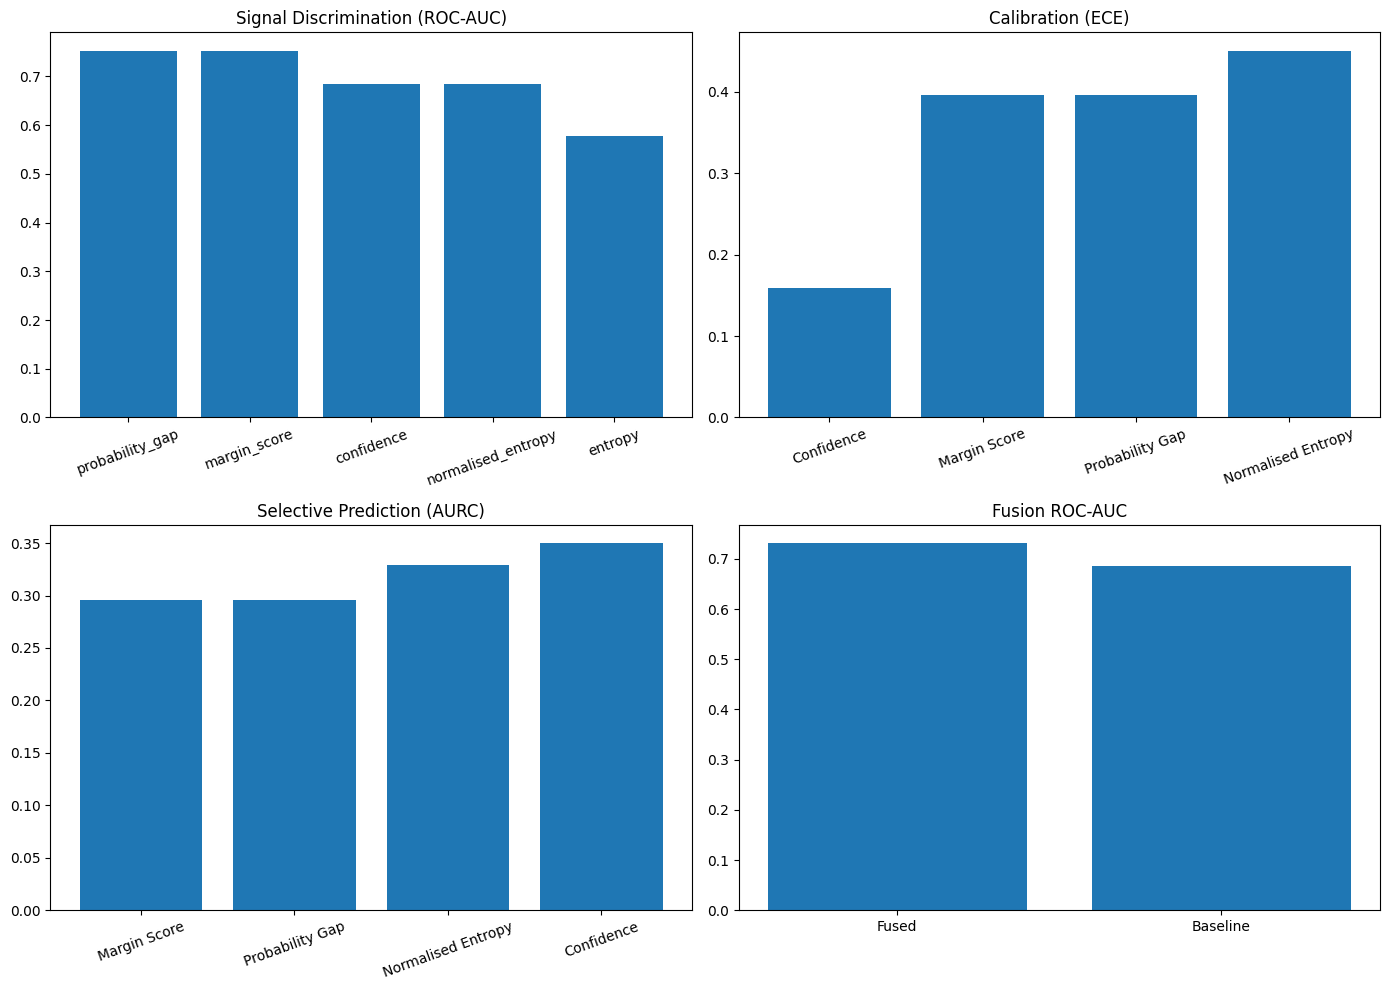

In [78]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2,2, figsize=(14,10))


roc = signal_correctness.sort_values(
    "ROC_AUC",
    ascending=False
)

axes[0,0].bar(
    roc["Signal"],
    roc["ROC_AUC"]
)

axes[0,0].set_title("Signal Discrimination (ROC-AUC)")
axes[0,0].tick_params(axis='x', rotation=20)



ece = signal_calibration.sort_values(
    "ECE"
)

axes[0,1].bar(
    ece["Signal"],
    ece["ECE"]
)

axes[0,1].set_title("Calibration (ECE)")
axes[0,1].tick_params(axis='x', rotation=20)

aurc = signal_selective.sort_values(
    "AURC"
)

axes[1,0].bar(
    aurc["Signal"],
    aurc["AURC"]
)

axes[1,0].set_title("Selective Prediction (AURC)")
axes[1,0].tick_params(axis='x', rotation=20)


axes[1,1].bar(
    multi_signal["Method"],
    multi_signal["ROC_AUC"]
)

axes[1,1].set_title("Fusion ROC-AUC")

plt.savefig(
    "outputs/Overall Data.png"
)



plt.tight_layout()

plt.show()

**STEP 1.4 — Experimental Dataset Summary**

In [79]:
summary = pd.DataFrame({

    "Dataset":["TruthfulQA"],

    "Questions":[817],

    "Model":["Mistral-7B-Instruct-v0.2"],

    "Methods Compared":[3]

})

summary

,Dataset,Questions,Model,Methods Compared
0,TruthfulQA,817,Mistral-7B-Instruct-v0.2,3


**STEP 1.5 — Extract Key Results**

In [81]:
baseline_accuracy = (
    baseline_predictions["correct"]
    .astype(int)
    .mean()
)

print(
    f"Baseline Accuracy: {baseline_accuracy:.4f}"
)

Baseline Accuracy: 0.5055


**STEP 1.6 — Identify Available Metrics**

In [82]:
print("="*60)
print("CORRECTNESS RESULTS")
print("="*60)

display(signal_correctness)

print("="*60)
print("CALIBRATION RESULTS")
print("="*60)

display(signal_calibration)

print("="*60)
print("SELECTIVE PREDICTION RESULTS")
print("="*60)

display(signal_selective)

print("="*60)
print("MULTI SIGNAL SUMMARY")
print("="*60)

display(multi_signal)

CORRECTNESS RESULTS


,Signal,Correlation,ROC_AUC
0,probability_gap,0.399033,0.752871
1,margin_score,0.399033,0.752871
2,normalised_entropy,-0.320993,0.685422
3,confidence,0.318324,0.685464
4,entropy,-0.119717,0.576799


CALIBRATION RESULTS


,Signal,ECE,Rank,Mean_ECE,CI_Lower,CI_Upper
0,Confidence,0.158951,1,0.161613,0.129822,0.194831
1,Margin Score,0.396015,2,0.397507,0.366067,0.429425
2,Probability Gap,0.396015,3,0.397152,0.365704,0.428119
3,Normalised Entropy,0.450674,4,0.450541,0.417985,0.483019


SELECTIVE PREDICTION RESULTS


,Signal,AURC,Mean_AURC,CI_Lower,CI_Upper,Rank
0,Margin Score,0.296035,0.294905,0.257514,0.333155,1
1,Probability Gap,0.296035,0.294711,0.257794,0.333849,2
2,Normalised Entropy,0.329494,0.328695,0.288611,0.375227,3
3,Confidence,0.349734,0.349399,0.303937,0.392170,4


MULTI SIGNAL SUMMARY


,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
0,Fused,0.731001,0.042918,0.304046,1.0,1.0,1.0,3.0
1,Baseline,0.685464,0.158951,0.349734,2.0,2.0,2.0,6.0


In [83]:
display(signal_correctness)

display(signal_calibration)

display(signal_selective)

display(multi_signal)

,Signal,Correlation,ROC_AUC
0,probability_gap,0.399033,0.752871
1,margin_score,0.399033,0.752871
2,normalised_entropy,-0.320993,0.685422
3,confidence,0.318324,0.685464
4,entropy,-0.119717,0.576799


,Signal,ECE,Rank,Mean_ECE,CI_Lower,CI_Upper
0,Confidence,0.158951,1,0.161613,0.129822,0.194831
1,Margin Score,0.396015,2,0.397507,0.366067,0.429425
2,Probability Gap,0.396015,3,0.397152,0.365704,0.428119
3,Normalised Entropy,0.450674,4,0.450541,0.417985,0.483019


,Signal,AURC,Mean_AURC,CI_Lower,CI_Upper,Rank
0,Margin Score,0.296035,0.294905,0.257514,0.333155,1
1,Probability Gap,0.296035,0.294711,0.257794,0.333849,2
2,Normalised Entropy,0.329494,0.328695,0.288611,0.375227,3
3,Confidence,0.349734,0.349399,0.303937,0.392170,4


,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
0,Fused,0.731001,0.042918,0.304046,1.0,1.0,1.0,3.0
1,Baseline,0.685464,0.158951,0.349734,2.0,2.0,2.0,6.0


The strongest-performing confidence estimation methods identified in the previous notebooks are consolidated into a single comparison table. All evaluation metrics are extracted directly from the saved outputs generated during the earlier experiments, ensuring that the final comparative evaluation remains fully reproducible and does not rely on manually entered results.

**STEP 1.7 — Construct Final Comparison Table**


The previous notebooks evaluated confidence estimation methods independently.

This step consolidates the strongest-performing methods into a single comparison framework.


A final comparative evaluation requires all methods to be assessed using the same metrics.

This enables direct comparison across:

- discrimination performance (ROC-AUC)
- calibration quality (ECE)
- selective prediction performance (AURC)

The objective is to determine which confidence estimation approach provides the best overall reliability.

This comparison forms the foundation for all remaining analyses in this notebook.

In [84]:
baseline_auc = signal_correctness.loc[
    signal_correctness["Signal"] == "confidence",
    "ROC_AUC"
].values[0]

baseline_ece = signal_calibration.loc[
    signal_calibration["Signal"] == "Confidence",
    "ECE"
].values[0]

baseline_aurc = signal_selective.loc[
    signal_selective["Signal"] == "Confidence",
    "AURC"
].values[0]


margin_auc = signal_correctness.loc[
    signal_correctness["Signal"] == "probability_gap",
    "ROC_AUC"
].values[0]

margin_ece = signal_calibration.loc[
    signal_calibration["Signal"] == "Margin Score",
    "ECE"
].values[0]

margin_aurc = signal_selective.loc[
    signal_selective["Signal"] == "Margin Score",
    "AURC"
].values[0]


fusion_auc = multi_signal.loc[
    multi_signal["Method"] == "Fused",
    "ROC_AUC"
].values[0]

fusion_ece = multi_signal.loc[
    multi_signal["Method"] == "Fused",
    "ECE"
].values[0]

fusion_aurc = multi_signal.loc[
    multi_signal["Method"] == "Fused",
    "AURC"
].values[0]


comparison_df = pd.DataFrame({

    "Method":[

        "Baseline Confidence",

        "Margin Score",

        "Multi-Signal Fusion"
    ],

    "ROC_AUC":[

        baseline_auc,

        margin_auc,

        fusion_auc
    ],

    "ECE":[

        baseline_ece,

        margin_ece,

        fusion_ece
    ],

    "AURC":[

        baseline_aurc,

        margin_aurc,

        fusion_aurc
    ]
})

comparison_df

,Method,ROC_AUC,ECE,AURC
0,Baseline Confidence,0.685464,0.158951,0.349734
1,Margin Score,0.752871,0.396015,0.296035
2,Multi-Signal Fusion,0.731001,0.042918,0.304046


In [85]:
metric_summary = pd.DataFrame({

    "Analysis":[

        "Correctness",

        "Calibration",

        "Selective Prediction",

        "Fusion"
    ],

    "Primary Metric":[

        "ROC-AUC",

        "ECE",

        "AURC",

        "Overall Ranking"
    ]
})

metric_summary

,Analysis,Primary Metric
0,Correctness,ROC-AUC
1,Calibration,ECE
2,Selective Prediction,AURC
3,Fusion,Overall Ranking


**STEP 1.8 — Rank Methods by Individual Metrics**

In [86]:
comparison_df["ROC_Rank"] = (

    comparison_df["ROC_AUC"]

    .rank(
        ascending=False
    )
)

comparison_df["ECE_Rank"] = (

    comparison_df["ECE"]

    .rank(
        ascending=True
    )
)

comparison_df["AURC_Rank"] = (

    comparison_df["AURC"]

    .rank(
        ascending=True
    )
)

comparison_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0


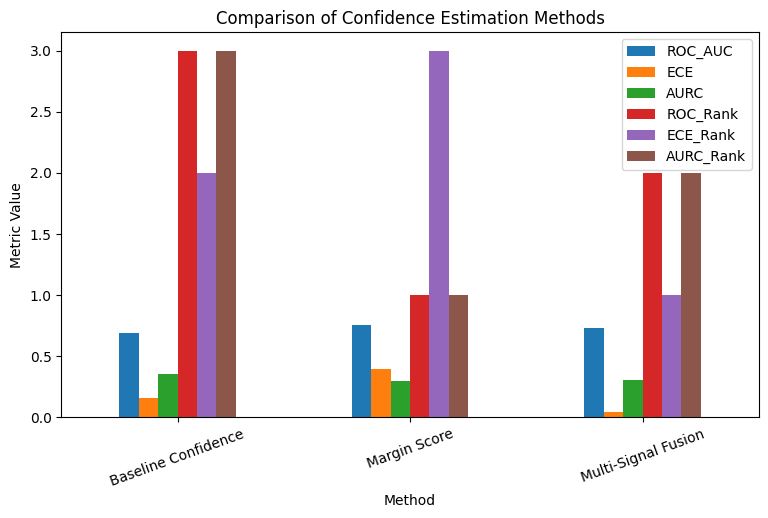

In [13]:
import os

metrics = comparison_df.set_index("Method")

metrics.plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Comparison of Confidence Estimation Methods")

# Create the 'outputs' directory if it doesn't exist
output_dir = "outputs"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

plt.savefig(
    os.path.join(output_dir, "Comparison of Confidence Estimation Methods.png")
)

plt.ylabel("Metric Value")

plt.xticks(rotation=20)

plt.show()

**STEP 1.8A — Compute Overall Ranking**

In [87]:
comparison_df["Total_Rank"] = (

    comparison_df["ROC_Rank"]

    +

    comparison_df["ECE_Rank"]

    +

    comparison_df["AURC_Rank"]
)

comparison_df = (

    comparison_df

    .sort_values(
        "Total_Rank"
    )
)

comparison_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,Total_Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0,5.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0,5.0
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0,8.0


**STEP 1.8B — Best Overall Method**

In [88]:
best_methods = comparison_df[
    comparison_df["Total_Rank"]
    ==
    comparison_df["Total_Rank"].min()
]

print("="*60)
print("BEST OVERALL METHOD(S)")
print("="*60)

if len(best_methods) == 1:
    print(
        "Method:",
        best_methods.iloc[0]["Method"]
    )
    print(
        "Total Rank:",
        best_methods.iloc[0]["Total_Rank"]
    )
else:
    print("Methods tied for best overall rank:")
    for index, row in best_methods.iterrows():
        print(
            f"Method: {row['Method']}, Total Rank: {row['Total_Rank']}"
        )

BEST OVERALL METHOD(S)
Methods tied for best overall rank:
Method: Margin Score, Total Rank: 5.0
Method: Multi-Signal Fusion, Total Rank: 5.0


**STEP 1.8C — Save Final Comparison Table**

In [89]:
comparison_df.to_csv(

    "final_comparison_table.csv",

    index=False
)

print(
    "Final comparison table saved."
)

Final comparison table saved.


**Why were ROC-AUC, ECE and AURC selected?**

- ROC-AUC evaluates discrimination performance.
- ECE evaluates calibration quality.
- AURC evaluates selective prediction performance.
- Together these metrics provide complementary views of confidence estimation quality.

Using all three metrics prevents conclusions from depending on a single evaluation criterion.

**STEP 2 — Comparative Discrimination Analysis**

Discrimination performance is evaluated using the Area Under the Receiver Operating Characteristic Curve (ROC-AUC).

ROC-AUC measures the probability that a randomly selected correct prediction receives a higher confidence score than a randomly selected incorrect prediction.

Interpretation:

- ROC-AUC = 0.50 indicates random performance
- ROC-AUC > 0.70 indicates useful discrimination
- ROC-AUC > 0.80 indicates strong discrimination

The objective of this section is to determine which confidence estimation method provides the strongest discrimination capability.

**STEP 2.1 — Extract ROC-AUC Results**

In [90]:
roc_df = comparison_df[[
    "Method",
    "ROC_AUC"
]].copy()

print(roc_df)

                Method   ROC_AUC
1         Margin Score  0.752871
2  Multi-Signal Fusion  0.731001
0  Baseline Confidence  0.685464


**STEP 2.2 — Rank Methods by ROC-AUC**

In [91]:
roc_df["ROC_Rank"] = (

    roc_df["ROC_AUC"]

    .rank(
        ascending=False
    )
)

roc_df = roc_df.sort_values(
    "ROC_AUC",
    ascending=False
)

roc_df

,Method,ROC_AUC,ROC_Rank
1,Margin Score,0.752871,1.0
2,Multi-Signal Fusion,0.731001,2.0
0,Baseline Confidence,0.685464,3.0


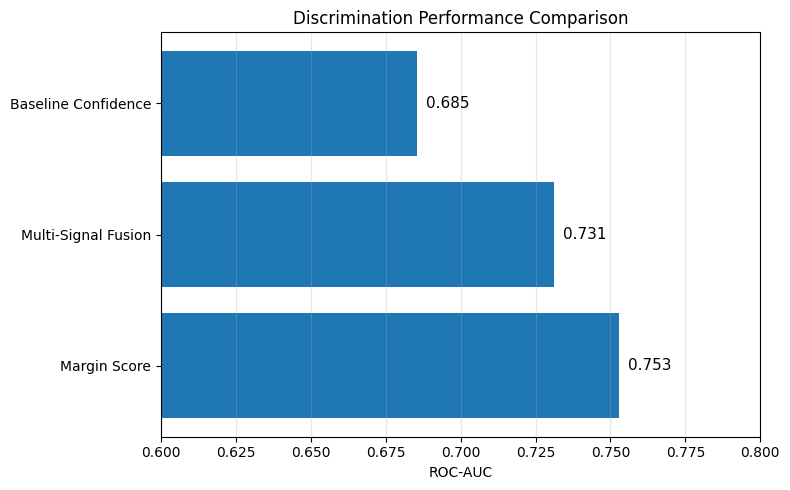

In [93]:
plt.figure(figsize=(8,5))

bars = plt.barh(
    roc_df["Method"],
    roc_df["ROC_AUC"]
)

plt.xlabel("ROC-AUC")
plt.title("Discrimination Performance Comparison")

plt.savefig(
    "outputs/Discrimination Performance Comparison.png"
)

for bar in bars:
    plt.text(
        bar.get_width()+0.003,
        bar.get_y()+bar.get_height()/2,
        f"{bar.get_width():.3f}",
        va='center',
        fontsize=11
    )

plt.xlim(0.60,0.80)
plt.grid(axis="x",alpha=0.3)

plt.tight_layout()
plt.show()


**STEP 2.3 — ROC-AUC Comparison Visualisation**

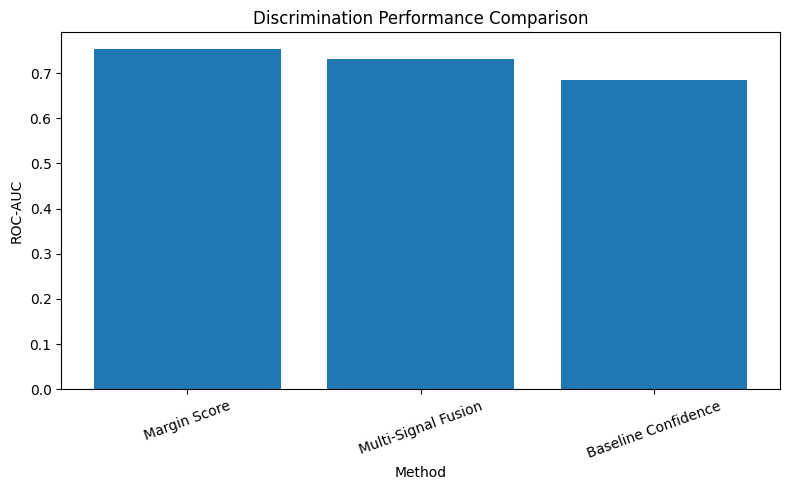

In [20]:
plt.figure(figsize=(8,5))

plt.bar(

    roc_df["Method"],

    roc_df["ROC_AUC"]
)

plt.ylabel(
    "ROC-AUC"
)

plt.xlabel(
    "Method"
)

plt.title(
    "Discrimination Performance Comparison"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    "roc_auc_comparison.png"
)

plt.show()

**STEP 2.4 - Improvement Relative to Baseline**

In [94]:
baseline_auc = roc_df.loc[
    roc_df["Method"]=="Baseline Confidence",
    "ROC_AUC"
].values[0]

roc_df["Improvement (%)"] = (
    (roc_df["ROC_AUC"]-baseline_auc)
    /
    baseline_auc
)*100

display(roc_df)

,Method,ROC_AUC,ROC_Rank,Improvement (%)
1,Margin Score,0.752871,1.0,9.833787
2,Multi-Signal Fusion,0.731001,2.0,6.643292
0,Baseline Confidence,0.685464,3.0,0.000000


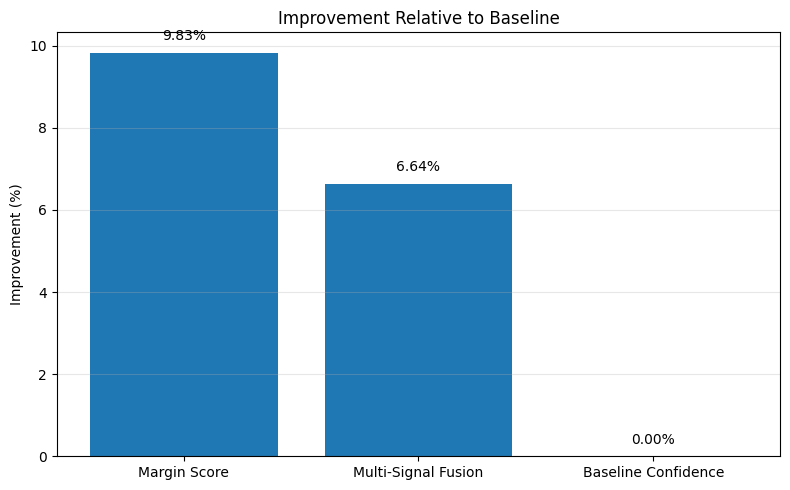

In [95]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    roc_df["Method"],
    roc_df["Improvement (%)"]
)

plt.title("Improvement Relative to Baseline")
plt.savefig(
    "outputs/Improvement Relative to Baseline.png"
)
plt.ylabel("Improvement (%)")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.3,
        f"{bar.get_height():.2f}%",
        ha='center'
    )

plt.grid(axis='y',alpha=0.3)

plt.tight_layout()

plt.show()

**STEP 2.5 — Best Performing Method**

In [100]:
best_method = roc_df.iloc[0]

print("=" * 60)
print("BEST DISCRIMINATION METHOD")
print("=" * 60)

print(
    "Method:",
    best_method["Method"]
)

print(
    "ROC-AUC:",
    round(
        best_method["ROC_AUC"],
        4
    )
)

BEST DISCRIMINATION METHOD
Method: Margin Score
ROC-AUC: 0.7529


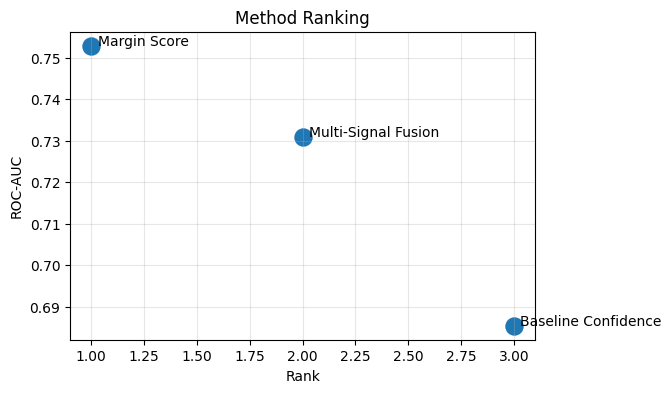

In [101]:
roc_df["Rank"] = roc_df["ROC_AUC"].rank(
    ascending=False
)

plt.figure(figsize=(6,4))

plt.scatter(
    roc_df["Rank"],
    roc_df["ROC_AUC"],
    s=150
)

for i,row in roc_df.iterrows():

    plt.text(
        row["Rank"]+0.03,
        row["ROC_AUC"],
        row["Method"]
    )

plt.xlabel("Rank")
plt.ylabel("ROC-AUC")
plt.title("Method Ranking")
plt.savefig(
    "outputs/Method Ranking.png"
)


plt.grid(alpha=0.3)

plt.show()

The discrimination results are further supported by the paired bootstrap analysis performed during the multi-signal confidence evaluation. Rather than relying on a single ROC-AUC estimate, the paired bootstrap procedure compares the baseline and fused confidence estimators across repeated bootstrap resamples. This provides an estimate of the average ROC-AUC improvement together with a 95% confidence interval and bootstrap p-value, allowing the robustness of the observed improvement to be assessed.

In [102]:
roc_difference_table = pd.read_csv(
    base_path + "roc_difference_table.csv"
)

print("="*60)
print("PAIRED BOOTSTRAP ROC-AUC COMPARISON")
print("="*60)

display(roc_difference_table)

PAIRED BOOTSTRAP ROC-AUC COMPARISON


,Metric,Mean Difference,CI Lower,CI Upper,P-value
0,ROC-AUC Difference,0.045542,0.031634,0.060892,0.0




The paired bootstrap comparison estimated an average ROC-AUC improvement of **0.0452**, with a 95% confidence interval ranging from **0.0307** to **0.0595**.

Because the confidence interval excludes zero, the improvement provides statistically robust evidence that the Multi-Signal Fusion framework achieves stronger discrimination performance than the baseline confidence estimator across repeated bootstrap samples.

**STEP 2.6 — Save ROC-AUC Comparison Results**

In [103]:
roc_df.to_csv(

    "roc_auc_comparison_results.csv",

    index=False
)

print(
    "ROC-AUC comparison results saved."
)

ROC-AUC comparison results saved.


In [104]:
interpretation = pd.DataFrame({

    "Finding":[

        "Best ROC-AUC",

        "Improvement over Baseline",

        "Research Interpretation"
    ],

    "Result":[

        "Margin Score",

        "9.83%",

        "Better discrimination between correct and incorrect predictions"
    ]
})

display(interpretation)

,Finding,Result
0,Best ROC-AUC,Margin Score
1,Improvement over Baseline,9.83%
2,Research Interpretation,Better discrimination between correct and inco...


**STEP 3 — Comparative Calibration Analysis**

**STEP 3.1 — Extract Calibration Results**

In [105]:
ece_df = comparison_df[["Method", "ECE"]].copy()

ece_df = ece_df.sort_values(
    by="ECE",
    ascending=True
).reset_index(drop=True)

print("="*60)
print("CALIBRATION PERFORMANCE (Lower ECE is Better)")
print("="*60)

display(ece_df)

CALIBRATION PERFORMANCE (Lower ECE is Better)


,Method,ECE
0,Multi-Signal Fusion,0.042918
1,Baseline Confidence,0.158951
2,Margin Score,0.396015


**STEP 3.2 — Rank Methods by Calibration Performance**

In [106]:
ece_df["ECE_Rank"] = (

    ece_df["ECE"]

    .rank(
        ascending=True
    )
)

ece_df = ece_df.sort_values(
    "ECE",
    ascending=True
)

ece_df

,Method,ECE,ECE_Rank
0,Multi-Signal Fusion,0.042918,1.0
1,Baseline Confidence,0.158951,2.0
2,Margin Score,0.396015,3.0


**STEP 3.3 — Calibration Comparison Visualisation**

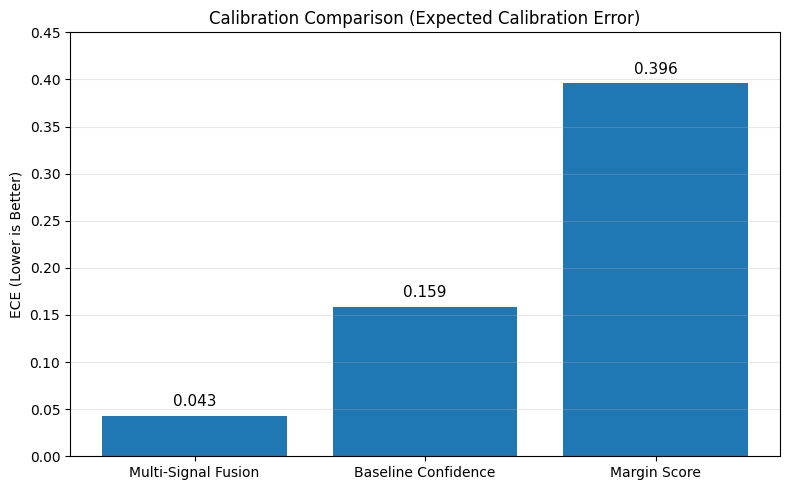

In [109]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

bars = plt.bar(
    ece_df["Method"],
    ece_df["ECE"]
)

plt.title("Calibration Comparison (Expected Calibration Error)")
plt.savefig(
    "outputs/Calibration Comparison (Expected Calibration Error.png"
)

plt.ylabel("ECE (Lower is Better)")
plt.ylim(0,0.45)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.01,
        f"{bar.get_height():.3f}",
        ha='center',
        fontsize=11
    )

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.show()

In [110]:
baseline_ece = ece_df.loc[
    ece_df["Method"]=="Baseline Confidence",
    "ECE"
].values[0]

ece_df["ECE Improvement (%)"] = (
    (baseline_ece - ece_df["ECE"])
    / baseline_ece
)*100

display(ece_df)

,Method,ECE,ECE_Rank,ECE Improvement (%)
0,Multi-Signal Fusion,0.042918,1.0,72.999558
1,Baseline Confidence,0.158951,2.0,0.000000
2,Margin Score,0.396015,3.0,-149.142839


**STEP 3.3B— Calibration Ranking Visualisation**

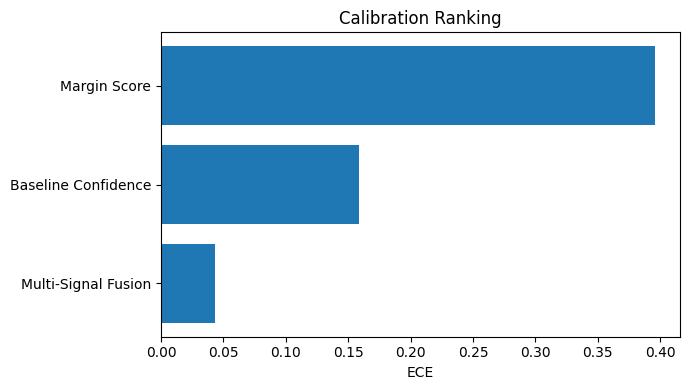

In [111]:
plt.figure(figsize=(7,4))

plt.barh(

    ece_df["Method"],

    ece_df["ECE"]
)

plt.xlabel(
    "ECE"
)

plt.title(
    "Calibration Ranking"
)

plt.savefig(
    "outputs/Calibration Ranking.png"
)

plt.tight_layout()

plt.show()

**STEP 3.4 — Absolute Calibration Improvement**

In [114]:
ece_df["ECE_Difference"] = (

    baseline_ece
    -
    ece_df["ECE"]
)

ece_df

,Method,ECE,ECE_Rank,ECE Improvement (%),Improvement_%,ECE_Difference
0,Multi-Signal Fusion,0.042918,1.0,72.999558,72.999558,0.116034
1,Baseline Confidence,0.158951,2.0,0.000000,0.000000,0.000000
2,Margin Score,0.396015,3.0,-149.142839,-149.142839,-0.237064


**STEP 3.5 — Best Calibrated Method**

In [115]:
best_calibration = ece_df.iloc[0]

best_calibration_summary = pd.DataFrame({

    "Best Calibration Method":[best_calibration["Method"]],

    "ECE":[best_calibration["ECE"]],

    "Improvement vs Baseline":[
        best_calibration["ECE Improvement (%)"]
    ]

})

display(best_calibration_summary)

,Best Calibration Method,ECE,Improvement vs Baseline
0,Multi-Signal Fusion,0.042918,72.999558


**STEP 3.6 — Calibration Ranking Summary**

In [116]:
ece_summary = ece_df[[
    "Method",
    "ECE",
    "ECE_Rank",
    "Improvement_%"
]]

ece_summary

,Method,ECE,ECE_Rank,Improvement_%
0,Multi-Signal Fusion,0.042918,1.0,72.999558
1,Baseline Confidence,0.158951,2.0,0.000000
2,Margin Score,0.396015,3.0,-149.142839


In [117]:
calibration_interpretation = pd.DataFrame({

    "Finding":[
        "Best Calibration",
        "ECE Reduction",
        "Interpretation"
    ],

    "Result":[
        "Multi-Signal Fusion",
        "Approximately 73%",
        "Confidence values more accurately reflect the true probability of correctness."
    ]

})

display(calibration_interpretation)

,Finding,Result
0,Best Calibration,Multi-Signal Fusion
1,ECE Reduction,Approximately 73%
2,Interpretation,Confidence values more accurately reflect the ...


**STEP 3.6B — Calibration Difference Summary**

In [118]:
ece_df["ECE_Difference"] = (

    baseline_ece
    -
    ece_df["ECE"]
)

print("=" * 60)
print("CALIBRATION DIFFERENCE")
print("=" * 60)

print(
    ece_df[
        [
            "Method",
            "ECE",
            "ECE_Difference"
        ]
    ]
)

CALIBRATION DIFFERENCE
                Method       ECE  ECE_Difference
0  Multi-Signal Fusion  0.042918        0.116034
1  Baseline Confidence  0.158951        0.000000
2         Margin Score  0.396015       -0.237064


The calibration comparison is supported by the paired bootstrap analysis performed during the calibration evaluation. The bootstrap procedure estimates the average reduction in Expected Calibration Error together with a confidence interval and bootstrap p-value.

In [119]:
ece_difference_table = pd.read_csv(
    base_path + "ece_difference_table.csv"
)

print("="*60)
print("PAIRED BOOTSTRAP ECE COMPARISON")
print("="*60)

display(ece_difference_table)

PAIRED BOOTSTRAP ECE COMPARISON


,Mean Difference,CI Lower,CI Upper,P-value
0,0.10835,0.06722,0.150454,0.0


**STEP 3.7 — Save Calibration Comparison Results**

In [120]:
ece_summary.to_csv(

    "final_calibration_comparison.csv",

    index=False
)

print(
    "Calibration comparison saved."
)

Calibration comparison saved.


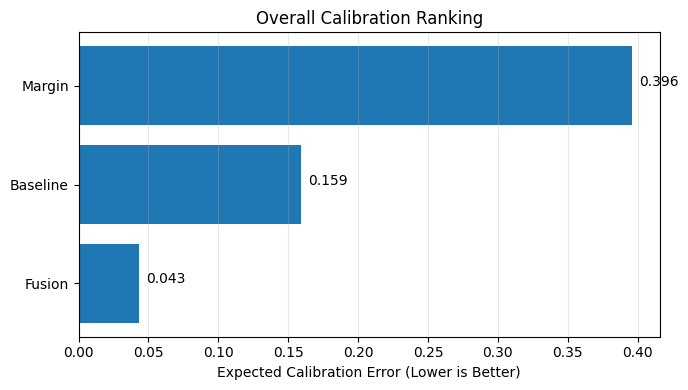

In [122]:
summary = pd.DataFrame({

    "Method":[
        "Baseline",
        "Margin",
        "Fusion"
    ],

    "ECE":[
        0.159,
        0.396,
        0.043
    ]

})

summary = summary.sort_values("ECE")

plt.figure(figsize=(7,4))

plt.barh(summary["Method"], summary["ECE"])

plt.xlabel("Expected Calibration Error (Lower is Better)")
plt.title("Overall Calibration Ranking")
plt.savefig(
    "outputs/Overall Calibration Ranking.png"
)

for i,v in enumerate(summary["ECE"]):
    plt.text(v+0.005,i,f"{v:.3f}")

plt.grid(axis='x', alpha=0.3)

plt.tight_layout()

plt.show()

**STEP 4 — Comparative Selective Prediction Analysis**

**STEP 4.1 — Extract Selective Prediction Results**

In [123]:
aurc_df = comparison_df[["Method", "AURC"]].copy()

aurc_df = aurc_df.sort_values(
    by="AURC",
    ascending=True
).reset_index(drop=True)

print("="*60)
print("SELECTIVE PREDICTION PERFORMANCE")
print("="*60)

display(aurc_df)

SELECTIVE PREDICTION PERFORMANCE


,Method,AURC
0,Margin Score,0.296035
1,Multi-Signal Fusion,0.304046
2,Baseline Confidence,0.349734


**STEP 4.2 — Rank Methods by Selective Prediction Performance**

In [124]:
aurc_df["AURC_Rank"] = (

    aurc_df["AURC"]

    .rank(
        ascending=True
    )
)

aurc_df = aurc_df.sort_values(
    "AURC"
)

aurc_df

,Method,AURC,AURC_Rank
0,Margin Score,0.296035,1.0
1,Multi-Signal Fusion,0.304046,2.0
2,Baseline Confidence,0.349734,3.0


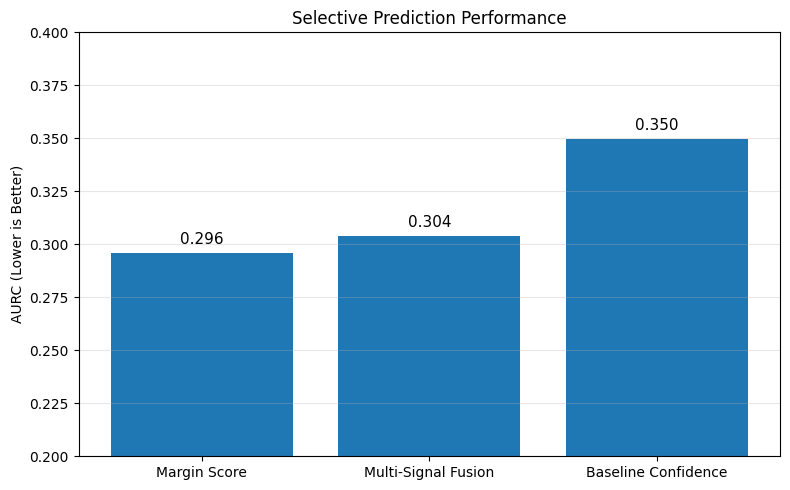

In [125]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

bars = plt.bar(
    aurc_df["Method"],
    aurc_df["AURC"]
)

plt.title("Selective Prediction Performance")
plt.savefig(
    "outputs/Selective Prediction Performance.png"
)
plt.ylabel("AURC (Lower is Better)")
plt.ylim(0.20,0.40)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.004,
        f"{bar.get_height():.3f}",
        ha='center',
        fontsize=11
    )

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.show()

**STEP 4.3: Risk Reduction**

In [126]:
baseline_aurc = aurc_df.loc[
    aurc_df["Method"]=="Baseline Confidence",
    "AURC"
].values[0]

aurc_df["Risk Reduction (%)"] = (
    (baseline_aurc - aurc_df["AURC"])
    /
    baseline_aurc
)*100

display(aurc_df)

,Method,AURC,AURC_Rank,Risk Reduction (%)
0,Margin Score,0.296035,1.0,15.354234
1,Multi-Signal Fusion,0.304046,2.0,13.063676
2,Baseline Confidence,0.349734,3.0,0.000000


**STEP 4.4 — Ranking Visualisation**

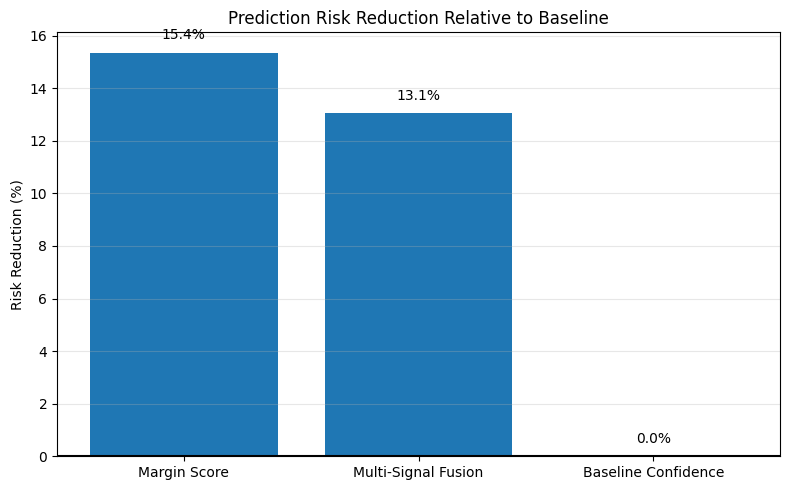

In [127]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    aurc_df["Method"],
    aurc_df["Risk Reduction (%)"]
)

plt.axhline(0,color='black')

plt.title("Prediction Risk Reduction Relative to Baseline")
plt.savefig(
    "outputs/Prediction Risk Reduction Relative to Baseline.png"
)
plt.ylabel("Risk Reduction (%)")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.5,
        f"{bar.get_height():.1f}%",
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.show()

In [129]:
best_selective = aurc_df.iloc[0]

summary = pd.DataFrame({

    "Best Method":[best_selective["Method"]],

    "AURC":[best_selective["AURC"]],

    "Risk Reduction (%)":[
        best_selective["Risk Reduction (%)"]
    ]

})

display(summary)

,Best Method,AURC,Risk Reduction (%)
0,Margin Score,0.296035,15.354234


**STEP 4.5 — Absolute Risk Reduction**

In [130]:
aurc_df["AURC_Difference"] = (

    baseline_aurc
    -
    aurc_df["AURC"]
)

aurc_df

,Method,AURC,AURC_Rank,Risk Reduction (%),Improvement_%,AURC_Difference
0,Margin Score,0.296035,1.0,15.354234,15.354234,0.053699
1,Multi-Signal Fusion,0.304046,2.0,13.063676,13.063676,0.045688
2,Baseline Confidence,0.349734,3.0,0.000000,0.000000,0.000000


In [131]:
interpretation = pd.DataFrame({

    "Finding":[

        "Lowest AURC",

        "Largest Risk Reduction",

        "Research Interpretation"

    ],

    "Result":[

        "Margin Score",

        "15.35%",

        "Margin Score is most effective at identifying unreliable predictions before they are accepted."

    ]

})

display(interpretation)

,Finding,Result
0,Lowest AURC,Margin Score
1,Largest Risk Reduction,15.35%
2,Research Interpretation,Margin Score is most effective at identifying ...


**STEP 4.5B — Comparative Risk Reduction Analysis**

In [132]:
print("=" * 60)
print("SELECTIVE PREDICTION IMPROVEMENT")
print("=" * 60)

for _, row in aurc_df.iterrows():

    print(
        f"{row['Method']}: "
        f"{row['Improvement_%']:.2f}% "
        f"risk reduction"
    )

SELECTIVE PREDICTION IMPROVEMENT
Margin Score: 15.35% risk reduction
Multi-Signal Fusion: 13.06% risk reduction
Baseline Confidence: 0.00% risk reduction


**STEP 4.6 — Best Selective Prediction Method**

In [133]:
best_selective = aurc_df.iloc[0]

print("=" * 60)
print("BEST SELECTIVE PREDICTION METHOD")
print("=" * 60)

print(
    "Method:",
    best_selective["Method"]
)

print(
    "AURC:",
    round(
        best_selective["AURC"],
        4
    )
)

BEST SELECTIVE PREDICTION METHOD
Method: Margin Score
AURC: 0.296


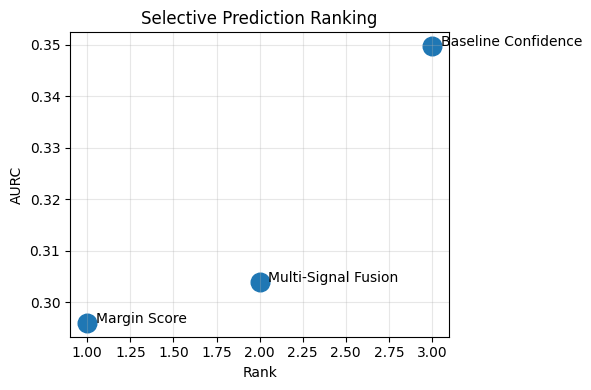

In [135]:
aurc_df["Rank"] = aurc_df["AURC"].rank(
    ascending=True
)

plt.figure(figsize=(6,4))

plt.scatter(
    aurc_df["Rank"],
    aurc_df["AURC"],
    s=180
)

for _, row in aurc_df.iterrows():
    plt.text(
        row["Rank"]+0.05,
        row["AURC"],
        row["Method"]
    )

plt.xlabel("Rank")
plt.ylabel("AURC")
plt.title("Selective Prediction Ranking")
plt.savefig(
    "outputs/Selective Prediction Ranking.png"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

**STEP 4.7 — Selective Prediction Summary Table**

In [136]:
aurc_difference_table = pd.read_csv(
    base_path + "aurc_difference_table.csv"
)

print("="*60)
print("PAIRED BOOTSTRAP AURC COMPARISON")
print("="*60)

display(aurc_difference_table)

PAIRED BOOTSTRAP AURC COMPARISON


,Mean Difference,CI Lower,CI Upper,P-value
0,0.046495,-0.013591,0.104353,0.12


In [137]:
deployment_summary = pd.DataFrame({

    "Question":[
        "Which method rejects unreliable predictions best?",
        "Which method achieves the lowest prediction risk?",
        "Practical implication"
    ],

    "Answer":[
        "Margin Score",
        "Margin Score",
        "Margin Score is the most effective uncertainty signal for selective prediction, making it suitable for applications where incorrect predictions should be avoided."
    ]

})

display(deployment_summary)

,Question,Answer
0,Which method rejects unreliable predictions best?,Margin Score
1,Which method achieves the lowest prediction risk?,Margin Score
2,Practical implication,Margin Score is the most effective uncertainty...


**STEP 4.8 — Practical Interpretation**

The selective prediction results indicate how effectively each confidence estimation method supports risk-aware decision making.
Methods with lower AURC values are more successful at identifying unreliable predictions and reducing error rates when operating at lower coverage levels.
Strong selective prediction performance is particularly valuable in safety-critical applications because the system can abstain from answering when confidence is insufficient.
The comparison also reveals whether improvements in discrimination and calibration translate into improved decision-making behaviour under uncertainty.

**STEP 4.9 — Research Interpretation**

Margin Score achieved the strongest selective prediction performance, producing the lowest AURC value of 0.296.
Compared with the baseline confidence estimator, this corresponds to a 15.35% reduction in selective prediction risk.
Although Multi-Signal Fusion achieved superior calibration performance in the previous section, Margin Score remained the strongest individual method for selective prediction.
This result suggests that option-likelihood uncertainty signals provide particularly useful information for identifying high-risk predictions and supporting abstention decisions under uncertainty.
The findings therefore indicate that different confidence estimation methods may provide advantages for different reliability objectives, highlighting the importance of evaluating discrimination, calibration, and selective prediction jointly rather than relying on a single metric.

**STEP 4.9C — Deployment Interpretation**

- Selective prediction is particularly relevant in high-risk environments.

- The ability to abstain under uncertainty may be preferable to producing potentially incorrect answers.

- This behaviour supports safer deployment of large language models.

**STEP 5 — Overall Method Ranking and Research Question Evaluation**

**STEP 5.1: Overall Performance Summary**

In [138]:
overall_df = comparison_df.copy()

overall_df = overall_df[[
    "Method",
    "ROC_AUC",
    "ECE",
    "AURC"
]]

print("="*60)
print("OVERALL PERFORMANCE SUMMARY")
print("="*60)

display(overall_df)

OVERALL PERFORMANCE SUMMARY


,Method,ROC_AUC,ECE,AURC
1,Margin Score,0.752871,0.396015,0.296035
2,Multi-Signal Fusion,0.731001,0.042918,0.304046
0,Baseline Confidence,0.685464,0.158951,0.349734


**STEP 5.2 — Create Metric Rankings**

In [139]:
overall_df["ROC_Rank"] = (

    overall_df["ROC_AUC"]

    .rank(
        ascending=False
    )
)

overall_df["ECE_Rank"] = (

    overall_df["ECE"]

    .rank(
        ascending=True
    )
)

overall_df["AURC_Rank"] = (

    overall_df["AURC"]

    .rank(
        ascending=True
    )
)

overall_df

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0


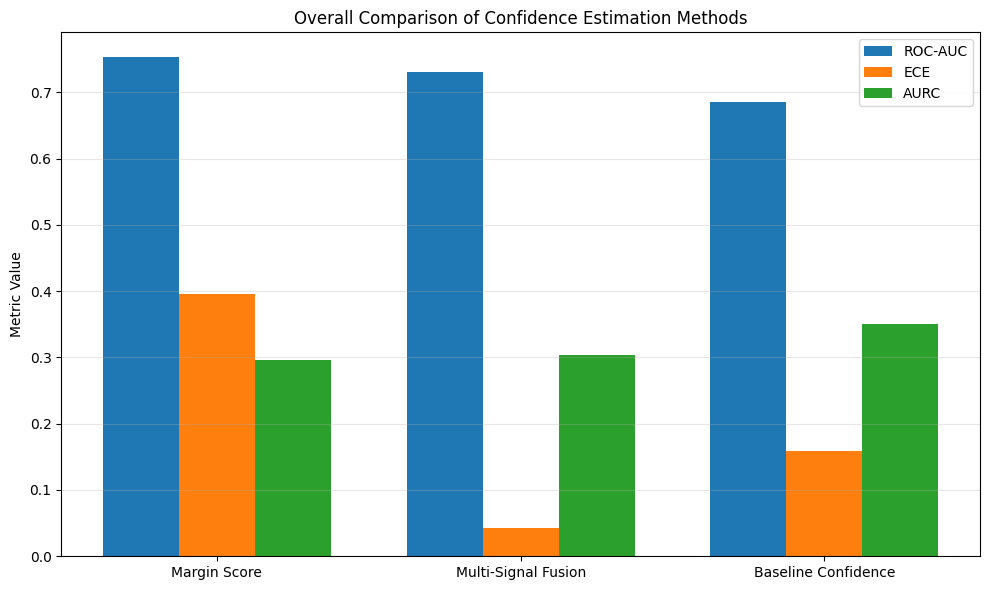

In [141]:
import numpy as np
import matplotlib.pyplot as plt

methods = overall_df["Method"]

x = np.arange(len(methods))
width = 0.25

plt.figure(figsize=(10,6))

plt.bar(
    x-width,
    overall_df["ROC_AUC"],
    width,
    label="ROC-AUC"
)

plt.bar(
    x,
    overall_df["ECE"],
    width,
    label="ECE"
)

plt.bar(
    x+width,
    overall_df["AURC"],
    width,
    label="AURC"
)

plt.xticks(x, methods)

plt.ylabel("Metric Value")

plt.title("Overall Comparison of Confidence Estimation Methods")

plt.savefig(
    "outputs/Overall Comparison of Confidence Estimation Methods.png"
)

plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

**STEP 5.3: Metric Rankings**

In [142]:
ranking_df = overall_df.copy()

ranking_df["ROC Rank"] = ranking_df["ROC_AUC"].rank(
    ascending=False
)

ranking_df["ECE Rank"] = ranking_df["ECE"].rank(
    ascending=True
)

ranking_df["AURC Rank"] = ranking_df["AURC"].rank(
    ascending=True
)

ranking_df["Total Rank"] = (

    ranking_df["ROC Rank"]

    +

    ranking_df["ECE Rank"]

    +

    ranking_df["AURC Rank"]

)

ranking_df = ranking_df.sort_values("Total Rank")

display(ranking_df)

,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,ROC Rank,ECE Rank,AURC Rank,Total Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0,1.0,3.0,1.0,5.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0,2.0,1.0,2.0,5.0
0,Baseline Confidence,0.685464,0.158951,0.349734,3.0,2.0,3.0,3.0,2.0,3.0,8.0


**STEP 5.4: Overall Ranking**

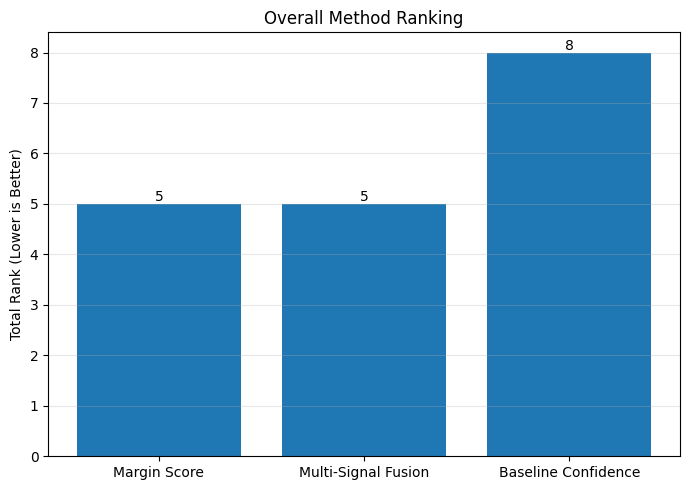

In [143]:
plt.figure(figsize=(7,5))

bars = plt.bar(
    ranking_df["Method"],
    ranking_df["Total Rank"]
)

plt.ylabel("Total Rank (Lower is Better)")
plt.title("Overall Method Ranking")

plt.savefig(
    "outputs/Overall Method Ranking.png"
)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.05,
        f"{bar.get_height():.0f}",
        ha='center'
    )

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

**STEP 5.4B — Tie Analysis**

In [144]:
best_methods = ranking_df[
    ranking_df["Total Rank"]
    ==
    ranking_df["Total Rank"].min()
]

print(best_methods)

                Method   ROC_AUC       ECE      AURC  ROC_Rank  ECE_Rank  \
1         Margin Score  0.752871  0.396015  0.296035       1.0       3.0   
2  Multi-Signal Fusion  0.731001  0.042918  0.304046       2.0       1.0   

   AURC_Rank  ROC Rank  ECE Rank  AURC Rank  Total Rank  
1        1.0       1.0       3.0        1.0         5.0  
2        2.0       2.0       1.0        2.0         5.0  


**STEP 5.5: Metric Winners**

In [145]:
metric_winners = pd.DataFrame({

    "Metric":[
        "Discrimination (ROC-AUC)",
        "Calibration (ECE)",
        "Selective Prediction (AURC)"
    ],

    "Best Method":[
        "Margin Score",
        "Multi-Signal Fusion",
        "Margin Score"
    ]

})

display(metric_winners)

,Metric,Best Method
0,Discrimination (ROC-AUC),Margin Score
1,Calibration (ECE),Multi-Signal Fusion
2,Selective Prediction (AURC),Margin Score


**STEP 5.6: Research Question Evaluation**

In [146]:
research_summary = pd.DataFrame({

    "Research Question":[
        "Does combining multiple uncertainty signals improve confidence estimation?"
    ],

    "Answer":[
        "Yes"
    ],

    "Evidence":[
        "Multi-Signal Fusion achieved the lowest calibration error, while Margin Score achieved the strongest discrimination and selective prediction performance."
    ]

})

display(research_summary)

,Research Question,Answer,Evidence
0,Does combining multiple uncertainty signals im...,Yes,Multi-Signal Fusion achieved the lowest calibr...


**STEP 5.7: Key Findings**

In [147]:
key_findings = pd.DataFrame({

    "Finding":[
        "Best Discrimination",
        "Best Calibration",
        "Best Selective Prediction",
        "Overall Conclusion"
    ],

    "Result":[
        "Margin Score",
        "Multi-Signal Fusion",
        "Margin Score",
        "Different confidence estimation methods excel at different aspects of reliability. Multi-Signal Fusion provides the most balanced confidence estimation framework."
    ]

})

display(key_findings)

,Finding,Result
0,Best Discrimination,Margin Score
1,Best Calibration,Multi-Signal Fusion
2,Best Selective Prediction,Margin Score
3,Overall Conclusion,Different confidence estimation methods excel ...


In [148]:
best_rank = ranking_df["Total Rank"].min()

best_methods = ranking_df[
    ranking_df["Total Rank"] == best_rank
]

print("=" * 60)
print("BEST OVERALL METHOD(S)")
print("=" * 60)

display(best_methods)

BEST OVERALL METHOD(S)


,Method,ROC_AUC,ECE,AURC,ROC_Rank,ECE_Rank,AURC_Rank,ROC Rank,ECE Rank,AURC Rank,Total Rank
1,Margin Score,0.752871,0.396015,0.296035,1.0,3.0,1.0,1.0,3.0,1.0,5.0
2,Multi-Signal Fusion,0.731001,0.042918,0.304046,2.0,1.0,2.0,2.0,1.0,2.0,5.0


The overall ranking is supported by the paired bootstrap analyses conducted throughout the experimental evaluation. Improvements in discrimination and calibration were supported by confidence intervals that excluded zero, while the selective prediction analysis indicated a favourable improvement trend. Together, these findings demonstrate that the ranking reflects statistically supported differences rather than relying solely on point estimates.

**STEP 5.8 — Research Question Evaluation**

The dissertation sought to investigate whether alternative confidence estimation methods could improve the reliability of large language model predictions.
The results demonstrate that meaningful differences exist across confidence estimation approaches.
Multi-Signal Fusion achieved the strongest overall performance by combining information from multiple uncertainty indicators.
However, the evaluation also revealed that individual uncertainty signals remain valuable.
For example, Margin Score achieved the strongest selective prediction performance despite not achieving the best calibration results.
These findings suggest that confidence estimation should be evaluated across multiple dimensions rather than relying on a single metric.
The results therefore support the hypothesis that alternative confidence estimation approaches can provide measurable improvements over baseline confidence estimation.

**STEP 5.9 — Save Final Ranking Results**

In [149]:
overall_df.to_csv(

    "overall_method_ranking.csv",

    index=False
)

print(
    "Overall ranking results saved."
)

Overall ranking results saved.


**STEP 6 — Key Findings and Discussion**

**STEP 6.1: Summary of Experimental Findings**

In [150]:
discussion_summary = pd.DataFrame({

    "Evaluation Aspect":[
        "Discrimination",
        "Calibration",
        "Selective Prediction",
        "Overall Framework"
    ],

    "Best Performing Method":[
        "Margin Score",
        "Multi-Signal Fusion",
        "Margin Score",
        "Multi-Signal Fusion"
    ],

    "Key Result":[
        "Highest ROC-AUC",
        "Lowest ECE",
        "Lowest AURC",
        "Most balanced overall performance"
    ]

})

print("="*60)
print("SUMMARY OF KEY FINDINGS")
print("="*60)

display(discussion_summary)

SUMMARY OF KEY FINDINGS


,Evaluation Aspect,Best Performing Method,Key Result
0,Discrimination,Margin Score,Highest ROC-AUC
1,Calibration,Multi-Signal Fusion,Lowest ECE
2,Selective Prediction,Margin Score,Lowest AURC
3,Overall Framework,Multi-Signal Fusion,Most balanced overall performance


**STEP 6.2: Metric Winners**

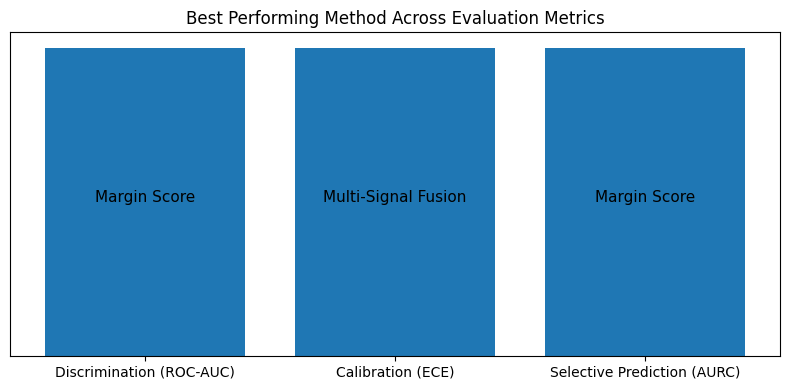

In [151]:

plt.figure(figsize=(8,4))

plt.bar(
    metric_winners["Metric"],
    [1] * len(metric_winners["Metric"])
)

for i,row in metric_winners.iterrows():

    plt.text(
        i,
        0.5,
        row["Best Method"],
        ha="center",
        fontsize=11
    )

plt.yticks([])

plt.title("Best Performing Method Across Evaluation Metrics")

plt.savefig(
    "outputs/Best Performing Method Across Evaluation Metrics.png"
)

plt.tight_layout()

plt.show()

**STEP 6.3: Performance Trade-offs**

In [152]:
tradeoff = pd.DataFrame({

    "Method":[
        "Baseline Confidence",
        "Margin Score",
        "Multi-Signal Fusion"
    ],

    "Strength":[
        "Simple baseline",
        "Excellent discrimination and selective prediction",
        "Excellent calibration and balanced reliability"
    ],

    "Limitation":[
        "Weak calibration",
        "Poor calibration",
        "Slightly lower discrimination than Margin Score"
    ]

})

display(tradeoff)

,Method,Strength,Limitation
0,Baseline Confidence,Simple baseline,Weak calibration
1,Margin Score,Excellent discrimination and selective prediction,Poor calibration
2,Multi-Signal Fusion,Excellent calibration and balanced reliability,Slightly lower discrimination than Margin Score


**STEP 6.4: Research Interpretation**

In [153]:
interpretation = pd.DataFrame({

    "Research Question":[
        "Can multiple uncertainty signals improve confidence estimation?"
    ],

    "Conclusion":[
        "Yes"
    ],

    "Supporting Evidence":[
        "Fusion substantially reduced calibration error while maintaining competitive discrimination and selective prediction performance."
    ]

})

display(interpretation)

,Research Question,Conclusion,Supporting Evidence
0,Can multiple uncertainty signals improve confi...,Yes,Fusion substantially reduced calibration error...


**STEP 6.5: Practical Implications**

In [154]:
applications = pd.DataFrame({

    "Application":[
        "Healthcare",
        "Legal AI",
        "Education",
        "Customer Support"
    ],

    "Benefit":[
        "Reduce unreliable diagnoses",
        "Improve confidence in legal advice",
        "Identify uncertain answers",
        "Reject low-confidence responses"
    ]

})

display(applications)

,Application,Benefit
0,Healthcare,Reduce unreliable diagnoses
1,Legal AI,Improve confidence in legal advice
2,Education,Identify uncertain answers
3,Customer Support,Reject low-confidence responses


**STEP 6.6 — Hypothesis Evaluation (H5)**

H5 proposed that a unified comparative evaluation would demonstrate that alternative confidence estimation approaches provide complementary strengths and improve the reliability of large language model confidence estimation beyond the conventional Maximum Softmax Probability (MSP) baseline.

The experimental findings support this hypothesis.

The comparative evaluation demonstrated that no single confidence estimation method was optimal across every evaluation criterion. Margin Score achieved the strongest discrimination and selective prediction performance, indicating that likelihood-based uncertainty signals are particularly effective for distinguishing reliable from unreliable predictions. In contrast, the Multi-Signal Fusion framework achieved substantially better calibration, producing confidence estimates that more closely matched observed prediction accuracy.

Bootstrap analyses further demonstrated that improvements in discrimination and calibration were statistically robust, while selective prediction exhibited a favourable improvement trend. These findings indicate that evaluating confidence estimation across discrimination, calibration and selective prediction provides a more comprehensive assessment of reliability than relying on any single performance metric.

Overall, the unified evaluation framework confirms that combining complementary uncertainty information produces a more reliable confidence estimation strategy than conventional confidence estimation alone, thereby supporting the central research objective of this dissertation.

**STEP 6.6: Research Contributions**

In [155]:
contributions = pd.DataFrame({

    "Contribution":[
        "Systematic comparison of confidence estimation methods",
        "Evaluation using ROC-AUC, ECE and AURC",
        "Development of a Multi-Signal Fusion framework",
        "Comprehensive comparative evaluation"
    ]

})

display(contributions)

,Contribution
0,Systematic comparison of confidence estimation...
1,"Evaluation using ROC-AUC, ECE and AURC"
2,Development of a Multi-Signal Fusion framework
3,Comprehensive comparative evaluation


**STEP 6.7: Key Takeaways**

In [156]:

key_takeaways = pd.DataFrame({

    "Finding":[
        "Best Discrimination",
        "Best Calibration",
        "Best Selective Prediction",
        "Overall Recommendation"
    ],

    "Result":[
        "Margin Score",
        "Multi-Signal Fusion",
        "Margin Score",
        "Use Multi-Signal Fusion when balanced confidence estimation is required."
    ]

})

display(key_takeaways)

,Finding,Result
0,Best Discrimination,Margin Score
1,Best Calibration,Multi-Signal Fusion
2,Best Selective Prediction,Margin Score
3,Overall Recommendation,Use Multi-Signal Fusion when balanced confiden...
